<!-- d2l:prose id=latent-diffusion-md-1 fw=all -->

# Latent Diffusion and Transformers

Running a diffusion model directly in pixel space evaluates the denoising network across every pixel at every sampling step. While $28 \times 28$ grayscale images contain only $784$ values, a $512 \times 512$ RGB photograph contains $786{,}432$, and as that section showed, most of these high-frequency dimensions carry imperceptible fine texture. *Latent diffusion* [@Rombach.Blattmann.Lorenz.ea.2022] separates perceptual compression from semantic generation: a variational autoencoder first compresses each image into a lower-dimensional spatial grid of *latents*, and the diffusion model trains and samples in this latent space at a fraction of the per-step FLOPs, running the decoder only once per generated sample.

A second architectural shift replaces the convolutional U-Net with a *diffusion transformer* (DiT) [@Peebles.Xie.2023] that processes the image or latent grid as a sequence of patch tokens modulated by adaptive layer normalization (`adaLN-Zero`). In this section we train a KL-regularized convolutional autoencoder on Fashion-MNIST, run velocity flow matching on its $7 \times 7 \times 4$ latents, diagnose the trade-off between decoder distortion and latent modelability [@Dieleman.2025], and compare U-Net and DiT backbones across compute scales.

In [1]:
import math
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from d2l import torch as d2l

In [2]:
torch.set_float32_matmul_precision('high')  # tf32 matmuls on tensor cores

<!-- d2l:prose id=latent-diffusion-md-2 fw=all -->

## Perceptual Compression

### The Cost of Pixels

Every sampling step evaluates the network on the whole image. A convolution
applies its kernel at every pixel, so the cost of a U-Net grows with the
number of pixels; attention compares every position with every other, so
its cost grows with their square. A $512 \times 512$ color image holds
$512 \cdot 512 \cdot 3 = 786{,}432$ numbers, and a sampler of fifty steps
touches each of them fifty times. Most of these numbers describe detail.
Write an image in a Fourier basis: the number of frequencies up to $k$
cycles per image grows like $k^2$, so most coordinates belong to fine
frequencies, and in that section the
power of Fashion-MNIST images fell by three orders of magnitude from one to
fourteen cycles per image. The many fine coordinates carry little of the
image's power.

Rate–distortion theory gives us the vocabulary for what to throw away: for
each level of distortion, the rate–distortion function is the fewest bits
per image that a code needs (that section). Which
bits a viewer misses is a question about people, not about squared error,
and @Rombach.Blattmann.Lorenz.ea.2022 answered it by observation: a
likelihood model of natural images spends most of its bits at the
low-distortion end of the curve, on details nobody perceives. They leave
this *perceptual compression* to an autoencoder, and the *semantic
compression*, the modeling of what the image shows, to the diffusion model.
The autoencoder of Stable Diffusion maps a $512 \times 512 \times 3$ image
to a $64 \times 64 \times 4$ latent, 48 times fewer numbers. Every diffusion
step works on the latent, and the decoder runs once per sample.

What makes a good latent? It must keep enough for the decoder to restore
the image and be easy for the diffusion model to learn, and the two pull
apart: a latent that stored every pixel would reconstruct perfectly and
be as hard to model as the pixels. @Dieleman.2025 names the three
quantities of this trade. The *rate* is how many numbers the latent has, the
*distortion* is how much the decoder loses, and the *modelability* is how
well a generative model of the latents does. Our autoencoder maps 784
numbers to a $7 \times 7$ grid with four channels, a rate of 196 numbers
(the figure).

![Latent diffusion. The encoder maps an image to a smaller latent, the diffusion model trains and samples on latents, and the decoder maps a sampled latent back to an image. Top: our autoencoder, from $28 \times 28 \times 1$ (784 numbers) to $7 \times 7 \times 4$ (196). Bottom: Stable Diffusion's, from $512 \times 512 \times 3$ (786,432) to $64 \times 64 \times 4$ (16,384).](../img/mdl-diffusion-latent-pipeline.svg)

### The Autoencoder

Modelability is the least obvious of the three, so let us say what a
diffusion model needs from a latent. It needs a known scale, against which
the noise of the Gaussian path is calibrated; no isolated outliers; and
nearby latents that decode to similar images, so that a slightly wrong
latent still gives a plausible image. An autoencoder trained only to
reconstruct guarantees none of this. Nothing stops it from storing its codes
at a scale of a thousand, or from decoding two neighboring codes to a shoe
and a shirt.

The variational autoencoder [@Kingma.Welling.2014] offers a remedy for
all three. The encoder outputs a mean $\boldsymbol\mu$ and a standard
deviation $\mathbf{s}$ for each of the 196 latent numbers, the latent is
drawn as $\mathbf{z} = \boldsymbol\mu + \mathbf{s} \odot \boldsymbol\xi$
with standard normal $\boldsymbol\xi$, and the decoder maps $\mathbf{z}$ to
a reconstruction $\hat{\mathbf{x}}$. The loss adds to the reconstruction
error a term that pulls each latent number toward a standard normal:

$$\mathcal{L}(\mathbf{x}) = \frac{1}{784}\,\|\mathbf{x} - \hat{\mathbf{x}}\|^2 + \frac{\beta}{196} \sum_{j=1}^{196} \tfrac{1}{2}\left(\mu_j^2 + s_j^2 - 1 - \log s_j^2\right).$$

The sum is the Kullback–Leibler divergence
$D_{\mathrm{KL}}\big(\mathcal{N}(\boldsymbol\mu, \mathrm{diag}(\mathbf{s}^2))
\,\|\, \mathcal{N}(\mathbf{0}, \mathbf{I})\big)$, the term of the evidence
lower bound (that section), and $\beta$ is its weight
(not the schedule's $\beta_k$). Read against the three needs, the loss does
two things. Pulling each $\mu_j$ toward zero and each $s_j$ toward one fixes
the scale and punishes outliers. Drawing $\mathbf{z}$ with noise of size
$\mathbf{s}$ during training shows the decoder codes that wander by about
$\mathbf{s}$, so it learns to decode them alike, which is the third need.

How much of this happens depends on $\beta$. With $\beta = 10^{-4}$, our
choice, the reconstruction stays in charge. At this weight the KL term fixes
the scale and keeps the encoder's noise from collapsing to zero, but it is
far too weak to make neighboring latents decode alike. Whether that matters
is not obvious, and we shall measure it below.

The autoencoders of large systems add more. They have usually trained with
a critic that scores image patches and with a perceptual loss, because
squared error averages plausible textures into a blur
(that section); a recent large autoencoder, ViTok-v2, dropped
the critic for a fixed perceptual loss when it scaled up
[@Hansen-Estruch.Chen.Ramanujan.ea.2026]. Ours needs neither, since
it keeps a quarter of the numbers of a small grayscale image on a black
background, while Stable Diffusion's keeps a forty-eighth of a photograph.
Other autoencoders quantize the latent into discrete tokens
[@Esser.Rombach.Ommer.2021; @Chang.Zhang.Jiang.ea.2022], which gives a
bounded code with no scale to calibrate and the kind of input that masked
diffusion (that section) works on.

Our autoencoder stacks the residual blocks of the U-Net, without an
embedding, at widths 64 and 128; its encoder halves the resolution twice to
a $7 \times 7$ grid with a mean and a log variance per latent channel, and
its decoder mirrors it.

In [3]:
class Autoencoder(nn.Module):
    """Residual convolutional autoencoder from 28x28x1 images to a 7x7
    Gaussian latent and back; returns the reconstruction and the KL term."""
    def __init__(self, latent_channels=4, ch=64, num_blocks=2):
        super().__init__()
        blocks = lambda a, b: [d2l.UNetBlock(a, b)] + [
            d2l.UNetBlock(b, b) for _ in range(num_blocks - 1)]
        down = lambda c: nn.Conv2d(c, c, 3, stride=2, padding=1)
        head = lambda a, b: [nn.GroupNorm(8, a), nn.SiLU(),
                             nn.Conv2d(a, b, 3, padding=1)]
        self.encoder = nn.Sequential(
            nn.Conv2d(1, ch, 3, padding=1), *blocks(ch, ch),
            down(ch), *blocks(ch, 2 * ch),                       # 14 x 14
            down(2 * ch), *blocks(2 * ch, 2 * ch),               # 7 x 7
            *head(2 * ch, 2 * latent_channels))  # mean and log variance
        self.decoder = nn.Sequential(
            nn.Conv2d(latent_channels, 2 * ch, 3, padding=1),
            *blocks(2 * ch, 2 * ch),
            nn.Upsample(scale_factor=2), *blocks(2 * ch, ch),    # 14 x 14
            nn.Upsample(scale_factor=2), *blocks(ch, ch),        # 28 x 28
            *head(ch, 1))

    def encode(self, x):
        mean, log_var = self.encoder(x).chunk(2, dim=1)
        return mean, log_var.clamp(-30, 20)

    def forward(self, x):
        mean, log_var = self.encode(x)
        z = mean + (0.5 * log_var).exp() * torch.randn_like(mean)
        kl = 0.5 * (mean ** 2 + log_var.exp() - 1 - log_var).mean()
        return self.decoder(z), kl

<!-- d2l:prose id=latent-diffusion-md-3 fw=all -->

We train it for 20,000 updates with `d2l.train_regression` of
that section, which runs Adam on a loss and returns
the trained model, a moving average of its weights and the losses. The
learning rate decays to zero along a cosine, so the final weights need no
averaging. A word on cost before we start: this section trains two
autoencoders and fourteen diffusion models for 20,000 updates each, and on
one RTX 4090 the whole notebook runs for about an hour and a half, far
longer on a CPU.

In [4]:
X, y, X_test, y_test = d2l.load_fashion_mnist_pm1()
dev = X.device

def batch_fn():
    return X[torch.randint(0, len(X), (128,), device=dev)]

def ae_loss(ae, x, beta=1e-4):
    x_hat, kl = ae(x)
    return ((x_hat - x) ** 2).mean() + beta * kl

torch.manual_seed(1)
ae, _, _ = d2l.train_regression(d2l.Autoencoder().to(dev), ae_loss, batch_fn,
                                20_000, cosine=True)
print(f'{d2l.num_params(ae) / 1e6:.2f}M parameters')

2.40M parameters


<!-- d2l:prose id=latent-diffusion-md-4 fw=all -->

The first row shows eight test images, the second the decoder's output for
their latent means.

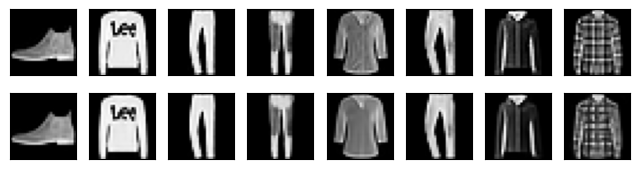

In [5]:
with torch.no_grad():
    x_hat = ae.decoder(ae.encode(X_test[:8])[0])
d2l.show_gray(torch.cat([X_test[:8], x_hat]), 2, 8);

<!-- d2l:prose id=latent-diffusion-md-5 fw=all -->

The reconstructions are hard to tell from the originals. To measure them we
use the Fréchet distance (FD) of that section, the
distance between Gaussians fitted to the features that a small classifier,
`d2l.FeatureCNN`, extracts from two sets of images. Two sets of real images
differ by chance too, so we print the FD between two disjoint sets of 5,000
test images as the *floor*. All FDs in this section use 5,000 images; at
1,000 the floor is about five times higher
(that section).

In [6]:
cnn = d2l.fashion_feature_cnn(X, y)
f_ref = d2l.fd_features(cnn, X_test[:5000])

def fd(imgs):
    """FD of images against the first 5,000 test images."""
    return d2l.fid_score(d2l.fd_features(cnn, imgs), f_ref)

print(f'floor, the other 5,000 test images: FD {fd(X_test[5000:]):.2f}')

floor, the other 5,000 test images: FD 0.17


<!-- d2l:prose id=latent-diffusion-md-6 fw=all -->

Using `fd`, we now encode and decode the remaining 5,000 test images
`X_test[5000:]` in batches to measure both the per-pixel squared reconstruction
error and the reconstruction Fréchet distance `fd_rec`:

In [7]:
x_hat = d2l.batched(lambda x: ae.decoder(ae.encode(x)[0]), X_test[5000:])
fd_rec = fd(x_hat)
print(f'reconstructions: squared error {((x_hat - X_test[5000:]) ** 2).mean():.4f}'
      f' per pixel, FD {fd_rec:.2f}')

reconstructions: squared error 0.0038 per pixel, FD 0.69


<!-- d2l:prose id=latent-diffusion-md-7 fw=all -->

The reconstructions score an FD of 0.6 to 0.8 against the floor of 0.17, at
a squared error of about 0.004 per pixel. This is the autoencoder's
distortion, and it is also the score of a perfect latent model: if the
diffusion model drew latents exactly as the encoder produces them, the
decoder would turn them into reconstructions, up to the encoder's small
noise. Every latent model below is read against this number. It is a
reference rather than a lower bound, for a reason the perturbation test
below will show.

We encode the training set once and print the standard deviation of the
latents, the average of the encoder's $\mathbf{s}$, and the excess kurtosis
of all latent values, which is zero for a normal distribution and large
when a few values lie far out.

In [8]:
encoded = d2l.batched(lambda x: torch.cat(ae.encode(x), 1), X)
mu, log_var = encoded.chunk(2, dim=1)       # mean and log variance
s = (0.5 * log_var).exp()
z = mu + s * torch.randn_like(mu)
scale = 1 / z.std().item()
kurtosis = (((z - z.mean()) * scale) ** 4).mean() - 3
print(f'latent std {z.std():.2f} (scale factor {scale:.2f}), encoder std '
      f'{s.mean():.3f}, excess kurtosis {kurtosis:.2f}')

latent std 0.94 (scale factor 1.06), encoder std 0.026, excess kurtosis -0.20


<!-- d2l:prose id=latent-diffusion-md-8 fw=all -->

The latents have a standard deviation slightly below one, so we multiply
them by a factor $c$ of about 1.05, which brings them to the unit variance
of the path's noise, and the excess kurtosis is near zero or negative:
there are no heavy tails. Two of the three needs are met. The encoder's
standard deviation is 0.02 to 0.03, so during training the decoder saw each
code blurred by about 3 percent of the latents' spread, and almost never by
more than a tenth. The third need, that slightly wrong latents decode to
plausible images, is the one this weak KL term does not supply.

## Diffusion in the Latent Space

### The Same Regression on Latents

With the autoencoder fixed, nothing changes but the data, which is the
attraction of the scheme: everything the earlier sections built carries
over. Each batch draws the latents of 128 training images, $\mathbf{z}_0 =
c\,(\boldsymbol\mu + \mathbf{s} \odot \boldsymbol\xi)$, fresh from the
encoder's distribution as @Rombach.Blattmann.Lorenz.ea.2022 do. We
train on the linear path of that section: we form
$\mathbf{z}_t = (1 - t)\,\mathbf{z}_0 + t\,\boldsymbol\epsilon$ and regress
the network's output onto the velocity $\boldsymbol\epsilon - \mathbf{z}_0$.

The scale factor matters because the path mixes the data with noise of unit
variance. Latents with a standard deviation of five would shift the
log-SNR at every time by $\log 25$ (Exercise
1), and Stable Diffusion multiplies its
latents by 0.18215 for this reason. The network is the U-Net of
that section with four input and output channels, and one
`loss_fn` serves images and latents.

In [9]:
path = d2l.GaussianPath.linear()
loss_fn = d2l.regression_loss(path, 'velocity')  # for images or latents

def latent_batch_fn():
    i = torch.randint(0, len(mu), (128,), device=dev)
    return (mu[i] + s[i] * torch.randn_like(mu[i])) * scale

torch.manual_seed(3)
_, unet_latent, _ = d2l.train_regression(
    d2l.UNet(ch=64, in_channels=4, out_channels=4).to(dev), loss_fn,
    latent_batch_fn, 20_000)

<!-- d2l:prose id=latent-diffusion-md-9 fw=all -->

As a reference we train the same U-Net on pixels. Both runs take 20,000
updates, twice the budget of that section, because the
transformers below need longer runs and this pixel model is their reference
too.

In [10]:
torch.manual_seed(4)
_, unet_pixel, _ = d2l.train_regression(d2l.UNet(ch=64).to(dev), loss_fn,
                                        batch_fn, 20_000)

<!-- d2l:prose id=latent-diffusion-md-10 fw=all -->

`sample` draws 5,000 samples from fixed noise with 50 Euler steps of
`d2l.ode_sample` (that section), and `decode`
undoes the scale factor and decodes latents. The first row below holds
samples of the pixel model, the second decoded samples of the latent model.

FD: pixel U-Net 1.54, latent U-Net 2.07


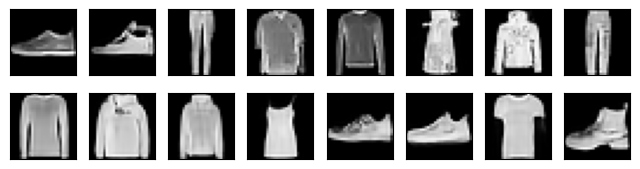

In [11]:
def sample(net, shape, n=5000):
    """n samples by 50 Euler steps from fixed noise, 1,000 at a time."""
    gen = torch.Generator(dev).manual_seed(0)
    noise = torch.randn(n, *shape, device=dev, generator=gen)
    pred = d2l.make_pred(net, path, 'velocity')
    return d2l.batched(lambda x: d2l.ode_sample(pred, x, path.sigma_bars(50)),
                       noise)

def decode(z):
    return d2l.batched(lambda z_k: ae.decoder(z_k / scale), z)

latent_shape, image_shape = (4, 7, 7), (1, 28, 28)
x_pixel = sample(unet_pixel, image_shape)
x_latent = decode(sample(unet_latent, latent_shape))
fd_pixel, fd_latent = fd(x_pixel), fd(x_latent)
print(f'FD: pixel U-Net {fd_pixel:.2f}, latent U-Net {fd_latent:.2f}')
d2l.show_gray(torch.cat([x_pixel[:8], x_latent[:8]]), 2, 8);

<!-- d2l:prose id=latent-diffusion-md-11 fw=all -->

Both rows show recognizable garments. The latent model scores an FD of
about 2 (2.0 to 2.2), the pixel model about 1.5. Both are unconditional, as
are all models of this section, so neither can be compared with the
class-conditional 0.8 of that section.

What did the latent model save? `train_step_gflops` counts the
floating-point operations of one training step, forward and backward on 128
inputs, in billions (GFLOP).

In [12]:
def train_step_gflops(net, loss_fn, shape, batch_size=128):
    """GFLOP of one training step, forward and backward, on a batch of zeros
    of the given shape."""
    # A local import, so that d2l needs nothing beyond its header's imports
    from torch.utils.flop_counter import FlopCounterMode
    x = torch.zeros(batch_size, *shape, device=next(net.parameters()).device)
    with FlopCounterMode(display=False) as counter:
        loss_fn(net, x).backward()
    return counter.get_total_flops() / 1e9

<!-- d2l:prose id=latent-diffusion-md-12 fw=all -->

Evaluating `train_step_gflops` on the four-channel latent U-Net
(`latent_shape`) and the single-channel pixel U-Net (`image_shape`) compares
their per-step arithmetic cost directly:

In [13]:
gflops_latent = d2l.train_step_gflops(
    d2l.UNet(ch=64, in_channels=4, out_channels=4).to(dev), loss_fn,
    latent_shape)
gflops_pixel = d2l.train_step_gflops(d2l.UNet(ch=64).to(dev), loss_fn,
                                     image_shape)
print(f'GFLOP per training step: latent U-Net {gflops_latent:.0f}, '
      f'pixel U-Net {gflops_pixel:.0f}')

GFLOP per training step: latent U-Net 15, pixel U-Net 203


<!-- d2l:prose id=latent-diffusion-md-13 fw=all -->

The latent U-Net needs about a dozen GFLOP per step, the pixel U-Net about
200. Every evaluation of the latent network, in training and at each
sampling step, costs less than a tenth of the arithmetic.

### Decoder Tolerance and Model Error

So the latent model is far cheaper and somewhat worse: its FD is about 1.4
times the pixel model's and about three times that of the reconstructions.
In Dieleman's terms, a rate of 196 numbers came with a distortion of 0.6 to
0.8, and the distance from there up to the samples measures modelability.
Where does that gap come from? Two causes suggest themselves. The latent
model may draw latents unlike the encoder's, which is its own error. Or it
may draw latents that are only slightly off, which a decoder trained on
codes moved by about 3 percent of the spread may turn into poor images. The
weak KL term makes the second cause plausible.

To tell the two apart, we build a decoder that tolerates wrong codes, check
that it does, and then train latent models on its latents. If intolerance
causes the gap, their samples should move toward the reconstructions. The
candidate is a second autoencoder, trained with ten times the KL weight.
The check decodes latents that are wrong on purpose: the latent means of
the other 5,000 test images plus Gaussian noise of $\sigma$ times the
latents' standard deviation. Let us predict the outcome first: the second
encoder should blur its codes more, so its decoder should tolerate larger
errors and reconstruct worse.

In [14]:
torch.manual_seed(9)
ae_10, _, _ = d2l.train_regression(
    d2l.Autoencoder().to(dev), lambda ae, x: ae_loss(ae, x, beta=1e-3),
    batch_fn, 20_000, cosine=True)

<!-- d2l:prose id=latent-diffusion-md-14 fw=all -->

`perturbed_decodes` prints the encoder's standard deviation in units of the
latents' standard deviation, the reconstruction error and FD, and for each
$\sigma$ the mean squared change of the decoded image and its FD.

In [15]:
def perturbed_decodes(ae, x, sigmas=(0.1, 0.3, 0.5)):
    """Decode the latent means of x, and the means plus Gaussian noise of
    sigma times their standard deviation."""
    mu, log_var = d2l.batched(lambda x: torch.cat(ae.encode(x), 1),
                              x).chunk(2, dim=1)
    x_rec = d2l.batched(ae.decoder, mu)
    print(f'  encoder std {(0.5 * log_var).exp().mean() / mu.std():.3f}, '
          f'reconstructions: error {((x_rec - x) ** 2).mean():.4f}, '
          f'FD {fd(x_rec):.2f}')
    gen = torch.Generator(dev).manual_seed(0)
    eps = torch.randn(mu.shape, device=dev, generator=gen)
    for sigma in sigmas:
        x_noisy = d2l.batched(ae.decoder, mu + sigma * mu.std() * eps)
        print(f'  sigma {sigma}: change {((x_noisy - x_rec) ** 2).mean():.4f} '
              f'per pixel, FD {fd(x_noisy):.2f}')

for beta, model in ((1e-4, ae), (1e-3, ae_10)):
    print(f'beta {beta:g}')
    perturbed_decodes(model, X_test[5000:])

beta 0.0001


  encoder std 0.028, reconstructions: error 0.0038, FD 0.69


  sigma 0.1: change 0.0023 per pixel, FD 0.55


  sigma 0.3: change 0.0205 per pixel, FD 0.71


  sigma 0.5: change 0.0545 per pixel, FD 3.46
beta 0.001


  encoder std 0.194, reconstructions: error 0.0041, FD 0.96


  sigma 0.1: change 0.0027 per pixel, FD 0.87


  sigma 0.3: change 0.0232 per pixel, FD 0.54


  sigma 0.5: change 0.0619 per pixel, FD 1.33


<!-- d2l:prose id=latent-diffusion-md-15 fw=all -->

Both predictions hold. The tenfold weight makes the encoder blur each code
by about a fifth of the latents' spread, seven times as much as before, and
its reconstructions score about 0.3 worse. At half the spread the weak
decoder's FD jumps above 3, while the tolerant one stays near 1.3. Yet the
decoded images change by about as much in both, 0.053 to 0.055 per pixel
against 0.061 to 0.062. The stronger KL term has not taught the decoder to
ignore a wrong code. It has taught it to decode a wrong code into a
different but plausible garment, which is what a Fréchet distance rewards.

The printout holds a small surprise as well. For both autoencoders a little
noise lowers the FD below that of the reconstructions (at $\sigma = 0.1$ for
both, and further at $\sigma = 0.3$ for the tolerant one), although the
decoded images move away from the originals. A likely reason is that
decoding the mean of each code gives an image that is slightly too smooth,
an average over the codes the decoder saw in training, and that a little
noise restores some of the variety of real images; no cell here tests this.
Either way the printed numbers settle the point that matters: the
reconstruction FD is a reference, not a bound that no latent model can
pass.

Does the more tolerant decoder give better samples? `latent_unet_fd` runs
the recipe above on the latents of a given autoencoder, a latent U-Net
trained for 20,000 updates and sampled with 50 Euler steps, and returns the
FD of the decoded samples. We train two per autoencoder, from two seeds.

In [16]:
def latent_unet_fd(ae, seed):
    """FD of a latent U-Net trained on the latents of ae as above."""
    mu, log_var = d2l.batched(lambda x: torch.cat(ae.encode(x), 1),
                              X).chunk(2, dim=1)
    s = (0.5 * log_var).exp()
    c = 1 / (mu + s * torch.randn_like(mu)).std()   # the scale factor

    def latent_batch():
        i = torch.randint(0, len(mu), (128,), device=dev)
        return (mu[i] + s[i] * torch.randn_like(mu[i])) * c

    torch.manual_seed(seed)
    _, net, _ = d2l.train_regression(
        d2l.UNet(ch=64, in_channels=4, out_channels=4).to(dev), loss_fn,
        latent_batch, 20_000)
    z = sample(net, latent_shape)
    return fd(d2l.batched(lambda z_k: ae.decoder(z_k / c), z))

for beta, model in ((1e-4, ae), (1e-3, ae_10)):
    fds = [latent_unet_fd(model, seed) for seed in (10, 11)]
    print(f'beta {beta:g}: latent U-Net FD {fds[0]:.2f} and {fds[1]:.2f}')

beta 0.0001: latent U-Net FD 2.04 and 2.02


beta 0.001: latent U-Net FD 2.78 and 2.68


<!-- d2l:prose id=latent-diffusion-md-16 fw=all -->

It does not. Every latent U-Net on the tenfold weight scores worse than
every one on the weak weight, by about half a point (0.4 to 0.8). That is at
least two and a half times the spread between the two seeds of either, and
the samples of the tenfold autoencoder also sit further above its own
reconstructions. If intolerance were the cause, the tolerant decoder would
have narrowed the gap; in no run did it. The perturbation test adds a second
clue. Noise of half the latents' spread costs the tolerant decoder an FD of
only about 1.3, yet the latent models on its latents score 2.6 to 2.8. So
whatever these models get wrong, it is not a small random error on the
right latents: their errors are larger than that, or of another kind. At
our scale the gap is the latent model's own error.

That does not let the autoencoder off the hook. The same U-Net, trained by
the same recipe, did clearly worse on the latents of one encoder than on
those of the other, so the encoder decides how hard the latent model's job
is. This is Dieleman's modelability, a property of the autoencoder that
only a trained diffusion model can measure. The KL weight is therefore a
real choice, and here the small one is the right one: the stronger KL term
made both the reconstructions and the samples worse. Exercise
3 pushes the weight further in both directions.

What, then, makes a latent easy to model? Work since 2024 points less to
the KL weight than to what the latent represents. REPA
[@Yu.Kwak.Jang.ea.2025] adds a loss that aligns the hidden states of
the diffusion model with the features of a pretrained image encoder such as
DINOv2, and training reaches a given sample quality several times sooner.
Representation autoencoders [@Zheng.Ma.Tong.ea.2026] go further and
drop the KL-regularized encoder altogether: a frozen pretrained encoder
supplies the latent, and only a decoder is trained to invert it. Such a
latent has far more channels than a compressive one, which the reasoning
above would count against it, and yet a diffusion model learns it more
easily. In these latents nearby points stand for similar objects rather
than similar pixels. A latent organized by meaning, it seems, matters more
than one that is merely small and smooth.

At $28 \times 28$ the trade is not attractive. The pixel model is cheap
anyway, the autoencoder needs a training run of its own, and the latent
samples score worse.

## The Transformer Backbone

The U-Net builds in the assumptions of a convolutional network: nearby
pixels matter most, and the same features can appear anywhere. The vision
transformer of that section makes fewer of them, and on
image classification it trails convolutional networks when trained on
little data and overtakes them when pretrained on a great deal.
@Peebles.Xie.2023 asked whether the same holds for diffusion.

### Patches and Tokens

The DiT reads its input as the vision transformer does. It cuts the image
into $p \times p$ patches, maps each to a vector of width $d$ by a linear
map (a convolution with kernel size and stride $p$), adds a learned position
embedding, and passes the tokens through pre-norm transformer blocks
(that section). With $p = 4$ a $28 \times 28$ image
becomes 49 tokens of 16 pixels each; on our latents with $p = 1$, each of
the 49 grid positions is a token of four numbers.

The output differs from a classifier's. A denoiser returns a prediction of
the shape of its input, so the DiT maps every token by a final linear layer
to the values of its patch and reassembles the patches. Each token predicts
the velocity of its own patch, informed through attention by all the
others. With one token per pixel the image would have 16 times as many
tokens, and attention would cost 256 times as much.

### Adaptive Layer Norm

The transformer also needs the time $t$, and possibly a label. The U-Net of
that section solved this by adding a learned projection
of the embedded time and label to the feature maps of every block, one shift
per channel. Adaptive layer norm keeps the shift and adds a scale and a
gate.

A layer norm standardizes each token and applies a learned scale and shift.
In *adaptive layer norm* the scale $\mathbf{a}$ and the shift $\mathbf{b}$
are computed from the condition $\mathbf{c}$, the sum of a time embedding
and a label embedding, and the condition also sets a *gate* $\mathbf{g}$ on
each sublayer's output. One block computes

$$
\begin{aligned}
\mathbf{X} &\leftarrow \mathbf{X} + \mathbf{g}_1 \odot \mathrm{Attention}\big(\mathrm{LN}(\mathbf{X}) \odot (1 + \mathbf{a}_1) + \mathbf{b}_1\big),\\
\mathbf{X} &\leftarrow \mathbf{X} + \mathbf{g}_2 \odot \mathrm{MLP}\big(\mathrm{LN}(\mathbf{X}) \odot (1 + \mathbf{a}_2) + \mathbf{b}_2\big),
\end{aligned}
$$

where $\mathrm{LN}$ has no scale or shift of its own and the six vectors
come from one linear layer applied to $\mathrm{SiLU}(\mathbf{c})$, shared by
all tokens of an image. Thus one small matrix product per image turns each
feature of each sublayer up or down, differently at every noise level.

The linear layer starts at zero, hence the name *adaLN-Zero*. All gates are
then zero, every block computes the identity, and the final layer, also
zero, outputs zero. Training starts from a network that predicts zero
velocity everywhere, and each block comes into play as its gates grow
(the figure). Of everything in the block, the gates
that start at zero are the detail to remember. @Peebles.Xie.2023
compared this design with appending the condition as extra tokens, with
cross-attention to it, and with adaptive layer norm without the gates, and
adaLN-Zero gave the best samples of the four. Exercise
4 shows what the zero start does to the first two
thousand updates.

A time or a label is one vector per image, which suits adaptive layer
norm. A caption is a sequence of vectors, one per token from a frozen text
encoder, and for it cross-attention is the natural route. In
*cross-attention* the $m$ image tokens supply the queries and the $n$
caption tokens the keys and values, so the output has one row per image
token, the image's shape [@Rombach.Blattmann.Lorenz.ea.2022]; the
multimodal DiT of @Esser.Kulal.Blattmann.ea.2024 instead puts image
and caption tokens into one sequence. Dropping the caption at random during
training makes the empty caption the null label of classifier-free guidance
(that section).

![The diffusion transformer. Left: $4 \times 4$ patches become 49 tokens with learned positions. Middle: a DiT block; the condition $\mathbf{c}$, the sum of the time and label embeddings, sets a shift, a scale and a gate for each sublayer, and the gates start at zero. Right: a final adaptive layer norm and a zero-initialized linear layer map each token to its patch.](../img/mdl-diffusion-dit-block.svg)

`DiTBlock` builds the block on the `ViTBlock` of
that section, with `ada` as the linear map.

In [17]:
class DiTBlock(d2l.ViTBlock):
    """ViTBlock with adaLN-Zero: the condition c sets a shift, a scale and a
    gate for each sublayer; the gates start at zero."""
    def __init__(self, num_hiddens, mlp_num_hiddens, num_heads):
        super().__init__(num_hiddens, mlp_num_hiddens, num_heads, dropout=0.0,
                         use_bias=True)
        ln = lambda: nn.LayerNorm(num_hiddens, elementwise_affine=False,
                                  eps=1e-6)
        self.norm1, self.norm2 = ln(), ln()
        self.ada = nn.Sequential(nn.SiLU(),
                                 nn.Linear(num_hiddens, 6 * num_hiddens))
        nn.init.zeros_(self.ada[1].weight), nn.init.zeros_(self.ada[1].bias)

    def forward(self, X, c):
        shift1, scale1, gate1, shift2, scale2, gate2 = (
            self.ada(c)[:, None].chunk(6, dim=-1))
        X_mod = self.norm1(X) * (1 + scale1) + shift1
        X = X + gate1 * self.attention(X_mod, X_mod, X_mod)
        return X + gate2 * self.ffn(self.norm2(X) * (1 + scale2) + shift2)

<!-- d2l:prose id=latent-diffusion-md-17 fw=all -->

`DiT` adds the patch embedding, the learned positions, the time and label
embeddings, and the final adaptive layer norm and linear layer.

In [18]:
class DiT(nn.Module):
    """Diffusion transformer conditioned on a time t in [0, 1] and, with
    num_classes, on a label y; label num_classes means no label."""
    def __init__(self, img_size=28, patch_size=4, num_channels=1, width=256,
                 depth=6, num_heads=4, num_classes=None):
        super().__init__()
        self.width, self.num_classes = width, num_classes
        self.p, self.g = patch_size, img_size // patch_size
        self.patch = d2l.PatchEmbedding(img_size, patch_size, width,
                                        num_channels)
        self.pos = nn.Parameter(0.02 * torch.randn(1, self.g ** 2, width))
        self.time_mlp = d2l.make_mlp([width] * 3, nn.SiLU())
        self.label_emb = (nn.Embedding(num_classes + 1, width)
                          if num_classes else None)
        self.blks = nn.ModuleList([DiTBlock(width, 4 * width, num_heads)
                                   for _ in range(depth)])
        self.ln = nn.LayerNorm(width, elementwise_affine=False, eps=1e-6)
        self.ada = nn.Sequential(nn.SiLU(), nn.Linear(width, 2 * width))
        self.out = nn.Linear(width, patch_size ** 2 * num_channels)
        for m in (self.ada[1], self.out):
            nn.init.zeros_(m.weight), nn.init.zeros_(m.bias)

    def forward(self, x, t, y=None):
        c = self.time_mlp(d2l.time_embedding(t, self.width))
        if y is not None:
            c = c + self.label_emb(y)
        X = self.patch(x) + self.pos
        for blk in self.blks:
            X = blk(X, c)
        shift, scale = self.ada(c)[:, None].chunk(2, dim=-1)
        X = self.out(self.ln(X) * (1 + scale) + shift)  # (n, g*g, p*p*c)
        n, g, p = len(x), self.g, self.p  # tokens back to pixels
        X = X.reshape(n, g, g, p, p, -1).permute(0, 5, 1, 3, 2, 4)
        return X.reshape(n, -1, g * p, g * p)

<!-- d2l:prose id=latent-diffusion-md-18 fw=all -->

We build a DiT of width 256 and depth 6 with four heads, and pass eight
images and times through it.

In [19]:
dit = d2l.DiT().to(dev)       # width 256, depth 6, 4 heads, 4 x 4 patches
x, t = X[:8], torch.rand(8, device=dev)
with torch.no_grad():
    tokens, out = dit.patch(x), dit(x, t)
print('images', tuple(x.shape), '-> tokens', tuple(tokens.shape),
      '-> output', tuple(out.shape))
print(f'parameters: DiT {d2l.num_params(dit) / 1e6:.2f}M, '
      f'U-Net {d2l.num_params(d2l.UNet(ch=64)) / 1e6:.2f}M')
print('output at initialization all zero:', bool((out == 0).all()))

images (8, 1, 28, 28) -> tokens (8, 49, 256) -> output (8, 1, 28, 28)
parameters: DiT 7.39M, U-Net 1.20M
output at initialization all zero: True


<!-- d2l:prose id=latent-diffusion-md-19 fw=all -->

The untrained output is exactly zero, as promised. The DiT has 7.39
million parameters, six times as many as the U-Net, yet the scaling run
below finds the two about equal in arithmetic per step. The difference lies
in how each uses its weights: a convolution applies a few weights at
every one of many positions, while the DiT applies many weights to only 49
tokens.

### Scaling with Compute

Is the transformer better than the U-Net? At one size the question has no
general answer, since a larger network of either kind beats a smaller one.
What matters is how each improves as it grows. @Peebles.Xie.2023
trained DiTs of four sizes with three patch sizes each. At a fixed number of
training steps, FID fell steadily as the network's arithmetic per forward
pass grew, whether it came from a larger network or from smaller patches.
Their largest model, trained for seven million steps, set a new best FID on
class-conditional ImageNet at $256 \times 256$.

We repeat the measurement at our scale, for both backbones. Two DiTs grow
in width and depth together, with 64 dimensions per head as in most of the
paper's models: DiT-S (width 128, depth 4, two heads) and DiT-M, the model
above. Two U-Nets double their channels, from `ch=32` to the `ch=64` of the
pixel model above. Each is trained on pixels with the same loss and recipe
for 20,000 updates, twice from different seeds, and we measure its size by
the FLOPs of one training step.

In [20]:
sizes = {'DiT-S': dict(width=128, depth=4, num_heads=2),
         'DiT-M': dict(width=256, depth=6, num_heads=4)}
nets = {'DiT-S': lambda: d2l.DiT(**sizes['DiT-S']),
        'DiT-M': lambda: d2l.DiT(**sizes['DiT-M']),
        'U-Net 32': lambda: d2l.UNet(ch=32),
        'U-Net 64': lambda: d2l.UNet(ch=64)}
seeds = {'DiT-S': (5, 12), 'DiT-M': (6, 13), 'U-Net 32': (7, 14),
         'U-Net 64': (15,)}  # the first U-Net 64 is the pixel model above
runs = {name: dict(fd=[]) for name in nets}
runs['U-Net 64'].update(fd=[fd_pixel], imgs=x_pixel[:8])
for name, make_net in nets.items():
    for seed in seeds[name]:
        torch.manual_seed(seed)
        net = make_net().to(dev)
        _, ema, _ = d2l.train_regression(net, loss_fn, batch_fn, 20_000)
        imgs = sample(ema, image_shape)
        runs[name]['fd'].append(fd(imgs))
        runs[name].setdefault('imgs', imgs[:8])
    runs[name].update(params=d2l.num_params(net), gflops=d2l.train_step_gflops(
        net, loss_fn, image_shape))
for name, run in runs.items():
    print(f'{name:8} {run["params"] / 1e6:5.2f}M parameters '
          f'{run["gflops"]:4.0f} GFLOP per step   FD '
          + ', '.join(f'{v:.2f}' for v in run['fd']))

DiT-S     1.26M parameters   32 GFLOP per step   FD 4.82, 4.83
DiT-M     7.39M parameters  185 GFLOP per step   FD 1.89, 1.89
U-Net 32  0.34M parameters   51 GFLOP per step   FD 2.47, 2.52
U-Net 64  1.20M parameters  203 GFLOP per step   FD 1.54, 1.51


<!-- d2l:prose id=latent-diffusion-md-20 fw=all -->

We plot the mean FD of the two runs of each model against its FLOPs per
step, on logarithmic axes.

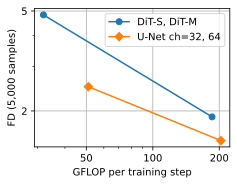

In [21]:
curves = [[runs['DiT-S'], runs['DiT-M']], [runs['U-Net 32'], runs['U-Net 64']]]
d2l.plot([[run['gflops'] for run in curve] for curve in curves],
         [[sum(run['fd']) / 2 for run in curve] for curve in curves],
         'GFLOP per training step', 'FD (5,000 samples)',
         legend=['DiT-S, DiT-M', 'U-Net ch=32, 64'], xscale='log',
         yscale='log', fmts=('o-', 'D-'))

<!-- d2l:prose id=latent-diffusion-md-21 fw=all -->

Each difference below is at least twice the spread between the two runs of
each model it involves, so three readings are firm. The first is the
surprise. DiT-S has as many parameters as the U-Net with `ch=64`, 1.26
against 1.20 million, and three times its FD; DiT-M, with six times the
parameters, still trails it. On $28 \times 28$ garments the assumptions
built into a convolution are worth more than a sixfold increase in
parameters.

Measured by compute, the U-Net is still ahead at both levels, if by less.
At the small end the U-Net with `ch=32`, at about 50 GFLOP per step, scores
about 2.5, and DiT-S, at a third less arithmetic, 4.5 to 4.9. Near 200 GFLOP
the U-Net scores about 1.5 and DiT-M 1.7 to 1.9. Yet the transformer gains
more as it grows: 5.8 times the compute divides the DiT's FD by 2.5 to 2.8,
while four times the compute divides the U-Net's by about 1.65. Its line on
the plot is the steeper one.

The rows below show the first eight samples of DiT-S, DiT-M and the two
U-Nets, drawn from the same noise.

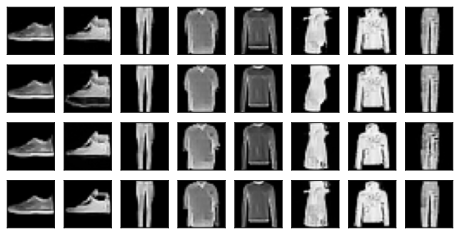

In [22]:
d2l.show_gray(torch.cat([run['imgs'] for run in runs.values()]), 4, 8);

<!-- d2l:prose id=latent-diffusion-md-22 fw=all -->

The four models mostly draw the same garment in each column, since each
integrates an ODE that sends a noise image to one image; in a column or two
the garment itself changes. Little in these eight columns would tell us
that the top row scores three times the FD of the bottom one. The Fréchet
distance compares thousands of samples through a classifier's features; our
eyes compare eight.

Our four points cannot show the claim that made the transformer the backbone at
scale: that it keeps improving over orders of magnitude of compute, by a recipe
as simple as making it wider and deeper. That trend is Peebles and Xie's, not
ours. Our plot shows the steeper slope but no crossing. What makes the transformer attractive beyond the
trend is that its arithmetic runs as large matrix products, so the methods that
train language models at scale carry over.

## Choice of Representation and Backbone

The two halves of the section meet in one last experiment. Does the
transformer help in the latent space? We train DiT-M on the latents with
patches of size 1, so that it sees 49 tokens, as it did on pixels, and
spends the same arithmetic per step, twelve to seventeen times that of the
latent U-Net.

In [23]:
torch.manual_seed(8)
net = d2l.DiT(img_size=7, patch_size=1, num_channels=4,
              **sizes['DiT-M']).to(dev)
_, dit_latent, _ = d2l.train_regression(net, loss_fn, latent_batch_fn, 20_000)
gflops = d2l.train_step_gflops(net, loss_fn, latent_shape)
print(f'latent DiT-M, {gflops:.0f} GFLOP per step: FD '
      f'{fd(decode(sample(dit_latent, latent_shape))):.2f}; latent U-Net '
      f'{fd_latent:.2f}; reconstructions {fd_rec:.2f}')

latent DiT-M, 185 GFLOP per step: FD 1.89; latent U-Net 2.07; reconstructions 0.69


<!-- d2l:prose id=latent-diffusion-md-23 fw=all -->

The latent DiT-M scores an FD of about 2 (1.8 to 2.2), about the same as
the latent U-Nets (1.9 to 2.2), and like them it lands at about three times
the reconstruction FD. Nor does the latent help the transformer here, since at equal compute the
latent DiT-M is no better than the pixel one, and the best pixel model beats
every latent model of the section.

When, then, is a latent worth its autoencoder? Its saving grows with the
number of pixels, and its costs, the autoencoder's distortion and a harder
modeling problem, do not. At $512 \times 512$ a U-Net on Stable Diffusion's
latent works on 64 times fewer positions, and its arithmetic falls by about
that factor: our pixel U-Net needed 13 to 18 times the arithmetic of the
latent one for sixteen times as many positions. The saving applies at every
training update and at every one of fifty sampling steps, and at that size
it outweighs the autoencoder's costs.

For a transformer the arithmetic is different. With patches of size 2 on the
$64 \times 64 \times 4$ latent a DiT sees 1,024 tokens; with patches of size 16
on the pixels it sees the same 1,024 tokens at almost the same cost (Exercise
2). The autoencoder saves the
transformer no tokens. It replaces a linear embedding of $16 \cdot 16 \cdot 3 =
768$ raw pixel values by a learned nonlinear one. A linear embedding of that
many values copes badly with noise, which fills all 768 dimensions while the
image lies near a set of much lower dimension. Two recent designs build pixel
transformers around this problem. @Li.He.2026 keep the large patches
and predict the clean image rather than the noise or the velocity (Exercise
6), and hourglass transformers
[@Crowson.Baumann.Birch.ea.2024] take the U-Net's multi-resolution shape
and attend only locally at the fine levels, so that their cost grows only
linearly with the pixels.

In summary: for low-resolution images where pixel-space diffusion fits the compute budget, diffuse pixels directly with a U-Net. For high-resolution images, diffuse latents from a lightly KL-regularized autoencoder, treating the autoencoder as a core part of the generative pipeline that governs both reconstruction distortion and latent modelability, and use a DiT backbone when scaling across large compute budgets.

## Summary

Latent diffusion compresses images via a KL-regularized autoencoder into a lower-dimensional spatial grid, rescales the latents to unit standard deviation, and runs standard diffusion or flow-matching regression in latent space. The autoencoder balances rate (latent dimension), distortion (reconstruction FD), and modelability (how easily the diffusion model learns the latent distribution): raising the KL weight $\beta$ makes the decoder more tolerant to random latent perturbations, yet degrades both reconstruction quality and generated sample FD. For the denoising backbone itself, a diffusion transformer (DiT) tokenizes the image or latent grid into patches and injects conditioning via `adaLN-Zero`, adaptive layer normalization with zero-initialized residual gates. At small compute budgets on $28 \times 28$ images, the convolutional U-Net outperforms DiT at equal FLOPs, whereas DiT exhibits a steeper improvement slope as compute per step scales.

## Exercises

1. **The scale of the latents.** The linear path mixes the data with noise
   of unit variance.
    1. Suppose each latent value has standard deviation $\varsigma$ instead
       of one. Show that its signal-to-noise ratio at time $t$ is
       $\varsigma^2 (1 - t)^2 / t^2$, so that the log-SNR is shifted by
       $\log \varsigma^2$ at every time.
    1. At which time does a latent with $\varsigma = 5$ have the
       signal-to-noise ratio that a latent with $\varsigma = 1$ has at
       $t = \tfrac12$? What fraction of uniformly drawn training times then
       falls where the signal still dominates the noise?
    1. [code] Train the latent U-Net on latents multiplied by $5c$ instead
       of $c$, and compare the decoded FD. Relate the result to how the
       schedule shifts with resolution
       (that section).
1. **Tokens at high resolution.** The autoencoder of Stable Diffusion maps
   a $512 \times 512 \times 3$ image to $64 \times 64 \times 4$.
    1. How many tokens does a DiT see with patches of size 2 on the latent,
       and with patches of size 16 on the pixels? How many numbers does each
       token carry in the two cases?
    1. A DiT block of width $d$ has about $12 d^2$ weights, and a training
       step costs about six FLOPs per weight and token, plus the attention.
       Estimate the FLOPs of one training step on a batch of 256 for a DiT
       of width 1,152 and depth 28 on the latents with patch 2. How large is
       the attention part?
    1. Repeat the estimate for patch 16 on the pixels. How much of the
       step's cost does the autoencoder save the transformer, and how much
       does it save a U-Net, whose cost grows with the number of positions?
1. [code] **Width and weight of the autoencoder.** The rate and the KL
   weight are the two settings of the autoencoder.
    1. Train autoencoders with 2, 4 and 8 latent channels, and report the
       reconstruction FD of each and the decoded FD of a latent U-Net
       trained on each. Which of the two numbers moves more, and does the
       gap between them close as the latent grows? What does this suggest
       about the four channels of Stable Diffusion's autoencoder, and the 16
       or more of later ones?
    1. Extend the perturbed-latent test of this section to
       $\beta \in \{0, 10^{-2}\}$, and print the latent standard deviation,
       the encoder's standard deviation and the excess kurtosis as well.
       With $\beta = 0$ nothing ties the scale of the latents to one. Why
       does the scale factor $c$ still make them usable?
    1. Train latent U-Nets on both new autoencoders. Does the ordering of
       the text, a smaller KL weight giving better samples, continue to
       $\beta = 0$?
1. [code] **Why start at zero.** Replace the zero initialization of the
   `ada` layers in `d2l.DiTBlock` and `d2l.DiT` by the framework's default
   initialization.
    1. Print the size of the output of the untrained network for both
       initializations.
    1. Train both DiT-M models for 2,000 updates and plot their losses.
       Explain the difference through the identity at initialization.
1. **Cross-attention as a lookup.** Image tokens
   $\mathbf{Y} \in \mathbb{R}^{m \times d}$ query caption tokens
   $\mathbf{X} \in \mathbb{R}^{n \times d}$: the queries are
   $\mathbf{Q} = \mathbf{Y}\mathbf{W}_q$, the keys
   $\mathbf{K} = \mathbf{X}\mathbf{W}_k$ and the values
   $\mathbf{V} = \mathbf{X}\mathbf{W}_v$, and the layer outputs
   $\mathrm{softmax}(\mathbf{Q}\mathbf{K}^\top / \sqrt{d})\,\mathbf{V}$.
    1. Show that each image position receives a convex combination of the
       caption's value vectors. With an empty caption of one token, show that
       every position receives the same vector, so that the unconditional
       prediction of guidance sees cross-attention as a learned constant
       shift.
    1. Suppose that the values were computed from the image instead,
       $\mathbf{V} = \mathbf{Y}\mathbf{W}_v$. What goes wrong with the shapes
       when $m \neq n$, and what would such a layer compute when $m = n$?
    1. In cross-attention the caption's keys and values do not depend on
       $\mathbf{x}_t$; in a multimodal DiT the caption tokens are updated by
       the image tokens in every block. For a caption of 77 tokens, 1,024
       image tokens and 50 steps with guidance, which caption-side
       computations can a cross-attention model do once per sample, and
       what fraction of a multimodal DiT's token computations belongs to the
       caption?

    *Part (b) is adapted from CMU 10-423/623,
    [Generative AI](https://www.cs.cmu.edu/~mgormley/courses/10423/),
    Homework 4, Question 2.3 (Spring 2026).*
1. [code] **Large patches and the clean-image target.** ● Train `DiT` on
   pixels with `patch_size=7`, so that each of its 16 tokens carries 49
   pixel values, at width 32 with one head and at width 256, for 10,000
   updates each. Give each width two output parameterizations under the
   same velocity loss: the network outputs the velocity, or it outputs
   $\hat{\mathbf{x}}_0$ and the velocity is formed as
   $(\mathbf{x}_t - \hat{\mathbf{x}}_0)/t$, with $t$ clamped below at
   $0.05$.
    1. Report the FD of the four models in a $2 \times 2$ table.
    1. Does the clean-image output help at width 32, where a token carries
       more values than the network has channels, and does the gap close at
       width 256?
    1. Explain the result with the argument of
       that section: an image lies near a set of
       much lower dimension than its pixel count, while the noise fills
       every dimension. Compare with the finding of @Li.He.2026 .

[Discussions](https://d2l.discourse.group/t/36892)